# Are new data-center proposals shifting rural over time?

The built-vs-pipeline divide piece (`dc_risk_divide.ipynb`) showed a snapshot: today's
206 zero-built/some-proposed ZIPs skew far more rural (69%) than the 1,196 ZIPs that
already host a facility (29%). This notebook adds the time axis Simon asked for: not
"where is the pipeline now" but "has the pipeline's own rural share moved over time."

Source: Compute Atlas's raw `statusHistory` (dated status-change entries per facility,
not carried into merascope's own merged product). ZIP-level trends aren't supportable
-- checked first: most ZCTAs with any dated record have exactly one, nowhere near
enough to fit a per-ZIP rate. National/period-level is real.

**Real bug caught and fixed, not just an addition:** the first version of this notebook
only kept records whose CURRENT status is proposed/permitted/under_construction. That
silently drops every proposal that has since been built (now "operational") or fallen
through (now "cancelled") -- and since older proposals have had more time to graduate
out of "forward" status than recent ones, this understates exactly the older years the
trend depends on (survivorship bias). Fixed: take the earliest dated forward-status
EVENT from a record's full `statusHistory`, regardless of its current status. Recovers
566 dated records vs. 498 before (+14%), concentrated in the earlier years as expected
(2021: 7->11, 2024: 48->67).

In [1]:
import json, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

sys.path.insert(0, str(Path("../../merascope/notebooks").resolve()))
import dcmodel as D

CA_PATH = Path("../../merascope/notebooks/cache/labels/ca_facilities.json").resolve()
recs = json.loads(CA_PATH.read_text())
print(f"{len(recs)} raw Compute Atlas records")

1280 raw Compute Atlas records


In [2]:
FORWARD = {"proposed", "permitted", "under_construction"}


def earliest_forward_date(rec):
    """Earliest dated statusHistory entry with a FORWARD status, from the record's
    FULL history -- not gated on the record's current status. A project proposed in
    2021 and built by 2023 still represents a real 2021 proposal event."""
    dates = [h.get("date") for h in (rec.get("statusHistory") or [])
             if h.get("status") in FORWARD and h.get("date")]
    norm = []
    for d in dates:
        m = re.match(r"^(\d{4})(-(\d{2}))?", d)
        if m:
            norm.append(f"{m.group(1)}-{m.group(3) or '01'}")
    return min(norm) if norm else None


rows = []
for r in recs:
    d = earliest_forward_date(r)
    if not d:
        continue
    loc = r.get("location") or {}
    if loc.get("lat") is None:
        continue
    rows.append({"id": r["id"], "current_status": r.get("status"), "date": d,
                 "lat": loc["lat"], "lon": loc["lon"]})

n_old_method = sum(1 for r in recs if r.get("status") in FORWARD)
print(f"OLD method (current status must be forward): would find <= {n_old_method} candidates")
print(f"NEW method (any record, earliest forward-status event ever): {len(rows)} dated records")

OLD method (current status must be forward): would find <= 640 candidates
NEW method (any record, earliest forward-status event ever): 566 dated records


## Spatial join to real ZCTAs (not the source's postal-code field)

Checked first, not assumed: Compute Atlas's own `location.postalCode` field is populated
for only 13 ZIPs across the whole dataset. Every dated record does carry real lat/lon
though, so joining those onto merascope's own ZCTA polygons (the same geometry the risk
model itself uses) recovers real rural/urban classification for far more of them.

**Rural definition corrected 2026-08-31**, replacing the earlier `pop_exposure_score_nat
> 0.9` proxy with USDA ERS's real 2020 ZIP-code RUCA codes (RUCA 1-3 = metro, 4-10 =
non-metro) -- the density proxy only had 69.9% national concordance with the actual
federal classification. See `dc_risk_divide.ipynb` for the concordance check.

In [3]:
gdf_pts = gpd.GeoDataFrame(
    rows, geometry=gpd.points_from_xy([r["lon"] for r in rows], [r["lat"] for r in rows]),
    crs="EPSG:4326",
)
zctas = D.load_zctas(verbose=False)
j = gpd.sjoin(gdf_pts, zctas[["zcta", "state", "pop_exposure_score_nat", "geometry"]],
              how="inner", predicate="within")
print(f"{len(j)}/{len(gdf_pts)} matched to a real ZCTA")

zip_counts = j["zcta"].value_counts()
one_record_share = (zip_counts == 1).mean()
print(f"{len(zip_counts)} distinct ZCTAs touched; {one_record_share:.0%} of them have exactly "
      f"1 dated record -- confirms ZIP-level rate-of-change isn't supportable, period-level is.")

j["year"] = j["date"].str[:4].astype(int)

ruca = pd.read_csv("../../merascope/notebooks/cache/labels/zcta_ruca_rural.csv",
                    dtype={"zcta": str})
j = j.merge(ruca[["zcta", "ruca_rural"]], on="zcta", how="left")
print(f"{j['ruca_rural'].isna().sum()} of {len(j)} matched ZCTAs have no RUCA code")
j["rural"] = j["ruca_rural"].fillna(False)  # USDA ERS RUCA, not the density proxy

ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


552/566 matched to a real ZCTA
454 distinct ZCTAs touched; 85% of them have exactly 1 dated record -- confirms ZIP-level rate-of-change isn't supportable, period-level is.
0 of 552 matched ZCTAs have no RUCA code


## Rural share by period

2021-2022 have too few dated records (n=7, n=15) to trust as their own points --
reported here for completeness but excluded from the headline table and the chart.

In [4]:
print("raw year-by-year (unbinned, includes the too-thin early years):")
for y, g in j.groupby("year"):
    print(f"  {y}: n={len(g):3d}  rural_share={g['rural'].mean():.1%}")

periods = [(0, 2023, "pre-2024"), (2024, 2024, "2024"), (2025, 2025, "2025"),
           (2026, 9999, "2026 (partial)")]
period_rows = []
for lo, hi, label in periods:
    g = j[(j["year"] >= lo) & (j["year"] <= hi)]
    n = len(g)
    share = g["rural"].mean()
    se = (share * (1 - share) / n) ** 0.5
    period_rows.append({"period": label, "n": n, "rural_share": share,
                        "ci_lo": max(0, share - 1.96 * se), "ci_hi": min(1, share + 1.96 * se)})
period_df = pd.DataFrame(period_rows)
print()
print(period_df.round(3))

assert period_df["n"].min() >= 47, "a period bucket got too thin to trust"

# reference: what's actually built today, from the live model table (not this raw feed)
df_full = D.load_model_table()
hosting = df_full["n_built"] > 0
ruca_full = pd.read_csv("../../merascope/notebooks/cache/labels/zcta_ruca_rural.csv",
                         dtype={"zcta": str})
df_full = df_full.merge(ruca_full[["zcta", "ruca_rural"]], on="zcta", how="left")
built_rural_share = df_full.loc[hosting, "ruca_rural"].fillna(False).mean()
print(f"\nreference line -- current built stock: {built_rural_share:.1%} rural (n={hosting.sum()}, RUCA)")

raw year-by-year (unbinned, includes the too-thin early years):
  2005: n=  1  rural_share=100.0%
  2010: n=  1  rural_share=100.0%
  2015: n=  2  rural_share=0.0%
  2017: n=  1  rural_share=100.0%
  2018: n=  3  rural_share=0.0%
  2019: n=  2  rural_share=0.0%
  2020: n=  1  rural_share=0.0%
  2021: n= 11  rural_share=18.2%
  2022: n= 19  rural_share=21.1%
  2023: n= 22  rural_share=27.3%
  2024: n= 66  rural_share=24.2%
  2025: n=178  rural_share=32.0%
  2026: n=245  rural_share=33.1%

           period    n  rural_share  ci_lo  ci_hi
0        pre-2024   63        0.238  0.133  0.343
1            2024   66        0.242  0.139  0.346
2            2025  178        0.320  0.252  0.389
3  2026 (partial)  245        0.331  0.272  0.390

reference line -- current built stock: 16.1% rural (n=1196, RUCA)


## Chart

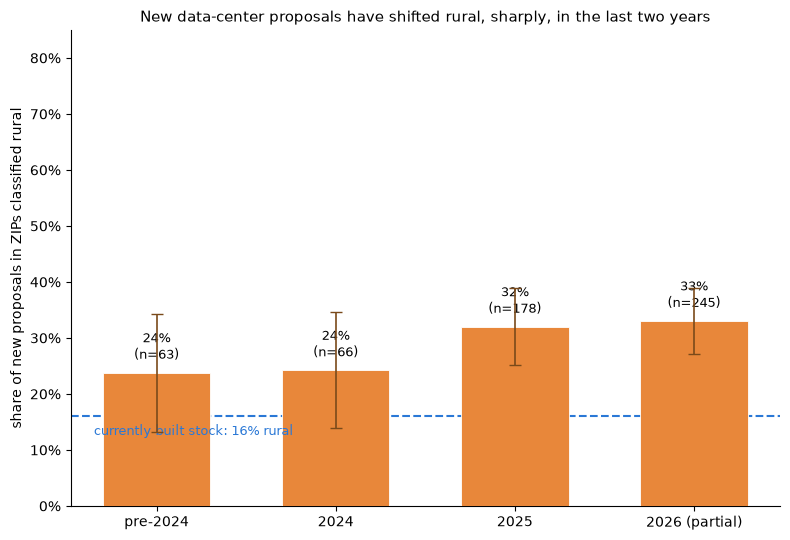

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(period_df))
vals = period_df["rural_share"] * 100
err_lo = vals - period_df["ci_lo"] * 100
err_hi = period_df["ci_hi"] * 100 - vals
bars = ax.bar(x, vals, color="#e8873a", edgecolor="white", linewidth=0.6, zorder=3, width=0.6)
ax.errorbar(x, vals, yerr=[err_lo, err_hi], fmt="none", ecolor="#7a4a1a", elinewidth=1.2,
            capsize=4, zorder=4)
for xi, v, n in zip(x, vals, period_df["n"]):
    ax.annotate(f"{v:.0f}%\n(n={n})", (xi, v), xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9)

ax.axhline(built_rural_share * 100, color="#2a78d6", linestyle="--", linewidth=1.5, zorder=2)
ax.annotate(f"currently built stock: {built_rural_share:.0%} rural", 
            (x[0] - 0.35, built_rural_share * 100), xytext=(0, -14), textcoords="offset points",
            fontsize=9, color="#2a78d6", ha="left")

ax.set_xticks(x)
ax.set_xticklabels(period_df["period"])
ax.set_ylabel("share of new proposals in ZIPs classified rural")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_ylim(0, 85)
ax.set_title("New data-center proposals have shifted rural, sharply, in the last two years",
             fontsize=11)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_proposal_rural_shift.png", dpi=150, bbox_inches="tight")
plt.show()